# 03 · Preprocessing Pipeline & Baseline

**Goal:** build the shared split and preprocessing (`src/prep.py`) that every model notebook uses, check that the
split is clean, and score the baseline that every model must beat.

Steps follow `docs/03_preprocessing_plan.md`: fixed rules first, then the split, then everything that learns from
the data inside a `Pipeline`, fit on the training set only (lesson 13).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyRegressor

sys.path.append('../src')
from prep import (load_data, split, add_model_top, linear_preprocessor, tree_preprocessor,
                  evaluate, save_result, NUM_COLS, CAT_COLS, MODEL_COL)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

## 1. Load the data and apply the fixed rules

`load_data()` runs the cleaning rules from `src/clean.py`, then two more rules that learn nothing from the data:

- an odometer under 100 miles on a car older than 1 year is a placeholder → set to missing;
- `cylinders` is a count stored as text ("6 cylinders") → `cylinders_num`; "other" → missing.

In [2]:
df = load_data()
print(df.shape)
print('odometer set to missing (placeholders):', df['odometer'].isna().sum())
print('cylinders_num missing:', df['cylinders_num'].isna().sum(), f"({df['cylinders_num'].isna().mean():.1%})")
df[NUM_COLS + CAT_COLS + ['model', 'price']].head()

(207644, 20)
odometer set to missing (placeholders): 1474
cylinders_num missing: 72853 (35.1%)


,car_age,odometer,cylinders_num,manufacturer,condition,fuel,title_status,transmission,drive,type,state,model,price
0,7,57923.0,8.0,gmc,good,gas,clean,other,NaN,pickup,al,sierra 1500 crew cab slt,33590
1,11,71229.0,8.0,chevrolet,good,gas,clean,other,NaN,pickup,al,silverado 1500,22590
2,1,19160.0,8.0,chevrolet,good,gas,clean,other,NaN,pickup,al,silverado 1500 crew,39590
3,4,41124.0,8.0,toyota,good,gas,clean,other,NaN,pickup,al,tundra double cab sr,30990
4,8,128000.0,6.0,ford,excellent,gas,clean,automatic,rwd,truck,al,f-150 xlt,15000


## 2. Train/test split (80/20)

A random split is used: the target is continuous (no classes to stratify), and all postings come from one month,
so there is no time order to respect. Reposts were removed **before** this step.

In [3]:
X_train, X_test, y_train, y_test = split(df)
print('train:', X_train.shape, '| test:', X_test.shape)

print(pd.DataFrame({'train': y_train.describe(), 'test': y_test.describe()}).round(0))

train: (166115, 19) | test: (41529, 19)
          train      test
count  166115.0   41529.0
mean    15933.0   16056.0
std     13779.0   13962.0
min      1000.0    1000.0
25%      6300.0    6250.0
50%     11950.0   11982.0
75%     21311.0   21500.0
max    150000.0  150000.0


Both sets have almost the same price distribution (median \$11,950 in train, \$11,982 in test).

### Leakage check: are copies of the same car on both sides?

If a reposted car slipped through the cleaning rules, its copy in the test set would be "seen" during training.
Count test rows whose price, year, manufacturer, model and odometer match a training row exactly:

In [4]:
key = ['price', 'year', 'manufacturer', 'model', 'odometer']
train_keys = set(map(tuple, pd.concat([X_train, y_train], axis=1)[key].dropna().values))
test_rows = pd.concat([X_test, y_test], axis=1)[key].dropna()
overlap = sum(tuple(r) in train_keys for r in test_rows.values)
print(f'Test rows with an exact match in train: {overlap} of {len(X_test):,} ({overlap / len(X_test):.2%})')

Test rows with an exact match in train: 0 of 41,529 (0.00%)


**No test car has an exact twin in the training set.** This check is what found the problem in the first
version of the cleaning rules: matching reposts only *within* one region left 9.5% of test cars with a copy in
training (private sellers post the same car in neighbouring cities, usually without a VIN). The repost rule in
`src/clean.py` now matches in any region, and the overlap is zero.

## 3. Car model: top 300 spellings + "other"

`model` has about 24,000 free-text spellings. The 300 most frequent (counted on the **training set only**) are
kept; the rest become "other". The test set uses the same list.

In [5]:
X_train, X_test = add_model_top(X_train, X_test)
covered = (X_train[MODEL_COL] != 'other').mean()
print(f'Training rows covered by the top-300 models: {covered:.1%}')
print('Examples:', X_train[MODEL_COL].value_counts().head(8).to_dict())

Training rows covered by the top-300 models: 54.5%
Examples: {'other': 75513, 'f-150': 3108, 'silverado 1500': 2017, '1500': 1660, 'camry': 1556, 'accord': 1538, 'civic': 1440, 'silverado': 1365}


## 4. The two preprocessors

| Step | Linear models (Linear / Ridge / Lasso / KNN) | Tree models (Decision Tree / Random Forest / Gradient Boosting) |
| --- | --- | --- |
| car_age | StandardScaler | as is |
| odometer | median impute → Yeo-Johnson | median impute |
| cylinders_num | median impute → StandardScaler | median impute |
| 9 categorical columns | missing → "unknown", one-hot (`drop='first'`) | missing → "unknown", one-hot |

Both are `ColumnTransformer`s, so inside a `Pipeline` they are fit on the training folds only.

In [6]:
lin = linear_preprocessor().fit(X_train)
tree = tree_preprocessor().fit(X_train)
print('Linear preprocessor output:', lin.transform(X_train.head()).shape[1], 'columns')
print('Tree preprocessor output  :', tree.transform(X_train.head()).shape[1], 'columns')

Xt = pd.DataFrame(lin.transform(X_train), columns=lin.get_feature_names_out())
Xt[['car_age', 'odometer', 'cylinders_num']].describe().round(2)

Linear preprocessor output: 430 columns
Tree preprocessor output  : 439 columns


,car_age,odometer,cylinders_num
count,166115.00,166115.00,166115.00
mean,0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.82,-2.51,-2.21
25%,-0.83,-0.67,0.12
50%,-0.18,0.08,0.12
75%,0.64,0.70,0.12
max,3.43,4.18,4.77


After the linear preprocessor the three numeric features have mean 0 and standard deviation 1, and no missing values.

## 5. Target: price or log(price)?

The EDA showed `price` is right-skewed (skew 2.07) and `log(price)` is nearly symmetric (−0.22). Models are trained
on `np.log(price)` and their predictions are turned back into dollars with `np.exp` before scoring, so every metric
is in dollars. Notebook 04 checks that this choice is better than raw price.

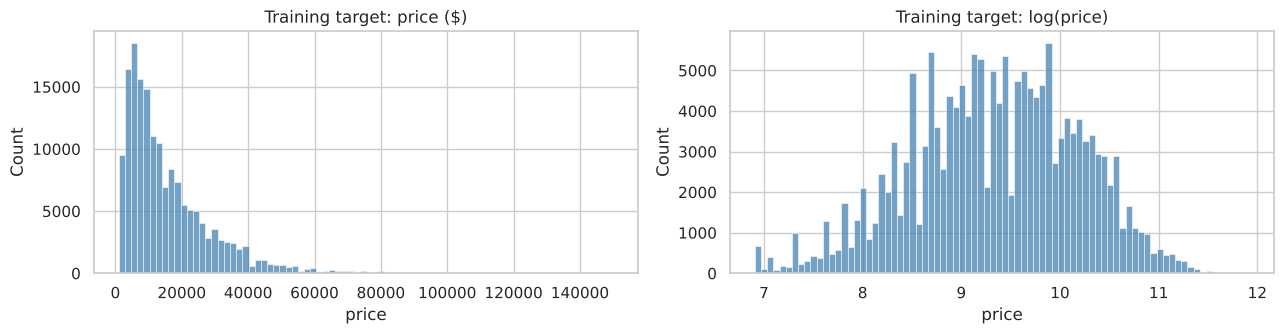

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
sns.histplot(y_train, bins=80, ax=axes[0], color='steelblue').set_title('Training target: price ($)')
sns.histplot(np.log(y_train), bins=80, ax=axes[1], color='steelblue').set_title('Training target: log(price)')
plt.tight_layout()
plt.show()

## 6. Baseline

The baseline predicts the same number for every car: the training **median** (best for MAE) or **mean**.
Any useful model must beat it clearly.

In [8]:
for strategy in ['median', 'mean']:
    base = DummyRegressor(strategy=strategy).fit(X_train, y_train)
    pred = base.predict(X_test)
    print(f'{strategy:6s} = ${pred[0]:,.0f}', {k: round(v, 3) for k, v in
          evaluate('', y_test, pred).items() if k not in ('model', 'target')})

median = $11,950 {'mae': 9675.191, 'rmse': 14552.936, 'r2': -0.087, 'mae_pct_of_median': np.float64(80.748), 'median_abs_error': np.float64(6650.0)}
mean   = $15,933 {'mae': 10203.862, 'rmse': 13962.155, 'r2': -0.0, 'mae_pct_of_median': np.float64(85.16), 'median_abs_error': np.float64(8933.72)}


In [9]:
base = DummyRegressor(strategy='median').fit(X_train, y_train)
save_result(evaluate('Baseline (median price)', y_test, base.predict(X_test), target='price'))

,model,target,mae,rmse,r2,mae_pct_of_median,median_abs_error
0,Baseline (median price),price,9675.191,14552.936,-0.086,80.748,6650.0


## 7. Summary

- **207,644 cars**: 166,115 for training, 41,529 for testing; the same split is used in every notebook. No car appears on both sides.
- 9 categorical features (including the top-300 car models) and 3 numeric features. One-hot encoding gives about
  430 columns for linear models and 440 for tree models.
- **Baseline (predict the median, \$11,950):** MAE **\$9,675**, R² −0.09. This is the number to beat.
- Results are saved to `results/metrics.csv`, which every model notebook updates.